# 04 · Models: baselines, logistic regression, boosted trees
**Project:** Next-day PM2.5 exceedance alerts for Chennai · CS3006 · pipeline stage **6 Model**

**Question for this stage:** *does a model forecast tomorrow's bad-air days better than simply
looking at today's PM2.5, and by how much?*

| Step | Data used |
|---|---|
| Tune each model's settings | forward-chaining folds inside 2021-23 (notebook 03) |
| Compare models, choose the alert threshold | 2024 (validation) |
| Final test | 2025, **not touched here** (stage 7) |

**Decision rule, written down before any model was trained** (stage-6 plan):
> pick the simplest model whose 2024 PR-AUC is within noise of the best; boosted trees win only if
> they clearly beat logistic regression; either model must beat the PM2.5-score baseline to be
> worth deploying.

§7 shows that the last condition was *not* met clearly, and records how the plan was adjusted
**before** looking at the test year.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))      # run from the notebooks/ folder

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import config as C, features as F, models as M, model_plots as MP
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
np.random.seed(C.RANDOM_SEED)

def show(fig_path):
    display(Image(str(fig_path)))

feats = F.make_features()
tr, va = F.model_rows(feats, "train"), F.model_rows(feats, "val")
print(f"train 2021-23: {len(tr)} rows, {int(tr.y.sum())} bad days | "
      f"validation 2024: {len(va)} rows, {int(va.y.sum())} bad days")

train 2021-23: 3506 rows, 215 bad days | validation 2024: 902 rows, 76 bad days


## 1 · The models and why

| Model | What it is | Why it is here |
|---|---|---|
| **Never alert** | always "no" | the "93% accurate but useless" floor |
| **Persistence** | alert if today > 60 | the problem statement's baseline |
| **Today's PM2.5 as a score** | rank days by today's PM2.5; the alert cut-off can move | the *fair* baseline for probability models: same idea as persistence, but its threshold can be tuned to the same recall target |
| **Logistic regression** (L2) | weighted sum of features → probability | simple, explainable, one weight per feature; L2 handles correlated features (notebook 03 §3) |
| **Gradient-boosted trees** | many small decision trees, each correcting the last | can learn interactions such as "humidity matters only in winter" (notebook 02 §7) |

**Metric for tuning and comparison: PR-AUC** (area under the precision-recall curve). It measures
how well bad days are ranked above normal days, without fixing an alert threshold, and it ignores
the easy true negatives that make accuracy look good. A no-skill model scores the base rate.

## 2 · Baselines on every evaluation year

In [2]:
rows = []
for label, d in [("2022 (CV fold 1)", tr[tr.target_date.dt.year == 2022]),
                 ("2023 (CV fold 2)", tr[tr.target_date.dt.year == 2023]),
                 ("2024 (validation)", va)]:
    y, b = d.y.to_numpy(), M.baseline_scores(d)
    pers = M.alert_metrics(y, b["persistence"] == 1)
    rows.append({"year": label, "bad days": int(y.sum()), "base rate": y.mean(),
                 "persistence recall": pers["recall"], "persistence precision": pers["precision"],
                 "PM2.5 score PR-AUC": M.average_precision_score(y, b["pm25_score"])})
base = pd.DataFrame(rows).set_index("year")
base

,bad days,base rate,persistence recall,persistence precision,PM2.5 score PR-AUC
year,,,,,
2022 (CV fold 1),67,0.062,0.627,0.636,0.591
2023 (CV fold 2),74,0.070,0.500,0.514,0.471
2024 (validation),76,0.084,0.632,0.640,0.653


Persistence is a strong forecaster: right about 50-64% of the time, catching 50-63% of bad days.
But it **cannot reach the 0.7 recall target**: it can only alert on days that are already bad.
The PM2.5 score can, by lowering its cut-off, at the cost of more false alarms. Every model below
has to beat **the PM2.5-score PR-AUC of 0.47-0.65**.

## 3 · Tuning on the forward-chaining folds

In [3]:
cv = {fam: M.cv_search(tr, fam) for fam in M.GRIDS}
best = {fam: M.best_params(cv[fam]) for fam in cv}
for fam, table in cv.items():
    print(f"\n{fam}: best settings = {best[fam]}")
    display(table.drop(columns="params"))


logreg: best settings = {'C_': 0.1, 'class_weight': None}


,C_,class_weight,PR-AUC fold 1 (2022),PR-AUC fold 2 (2023),mean PR-AUC
0,0.100,NaN,0.533,0.559,0.546
1,1.000,NaN,0.518,0.564,0.541
2,10.000,NaN,0.512,0.567,0.540
3,0.010,NaN,0.520,0.542,0.531
4,0.010,balanced,0.480,0.516,0.498
5,0.100,balanced,0.427,0.527,0.477
6,1.000,balanced,0.394,0.524,0.459
7,10.000,balanced,0.386,0.522,0.454



boosting: best settings = {'max_depth': 2, 'learning_rate': 0.05, 'max_iter': 100}


,max_depth,learning_rate,max_iter,PR-AUC fold 1 (2022),PR-AUC fold 2 (2023),mean PR-AUC
0,2,0.050,100,0.583,0.533,0.558
1,3,0.050,100,0.548,0.538,0.543
2,2,0.050,300,0.531,0.514,0.523
3,2,0.100,100,0.533,0.504,0.519
4,3,0.100,100,0.506,0.493,0.499
5,3,0.050,300,0.497,0.480,0.488
6,2,0.100,300,0.492,0.470,0.481
7,3,0.100,300,0.472,0.435,0.453


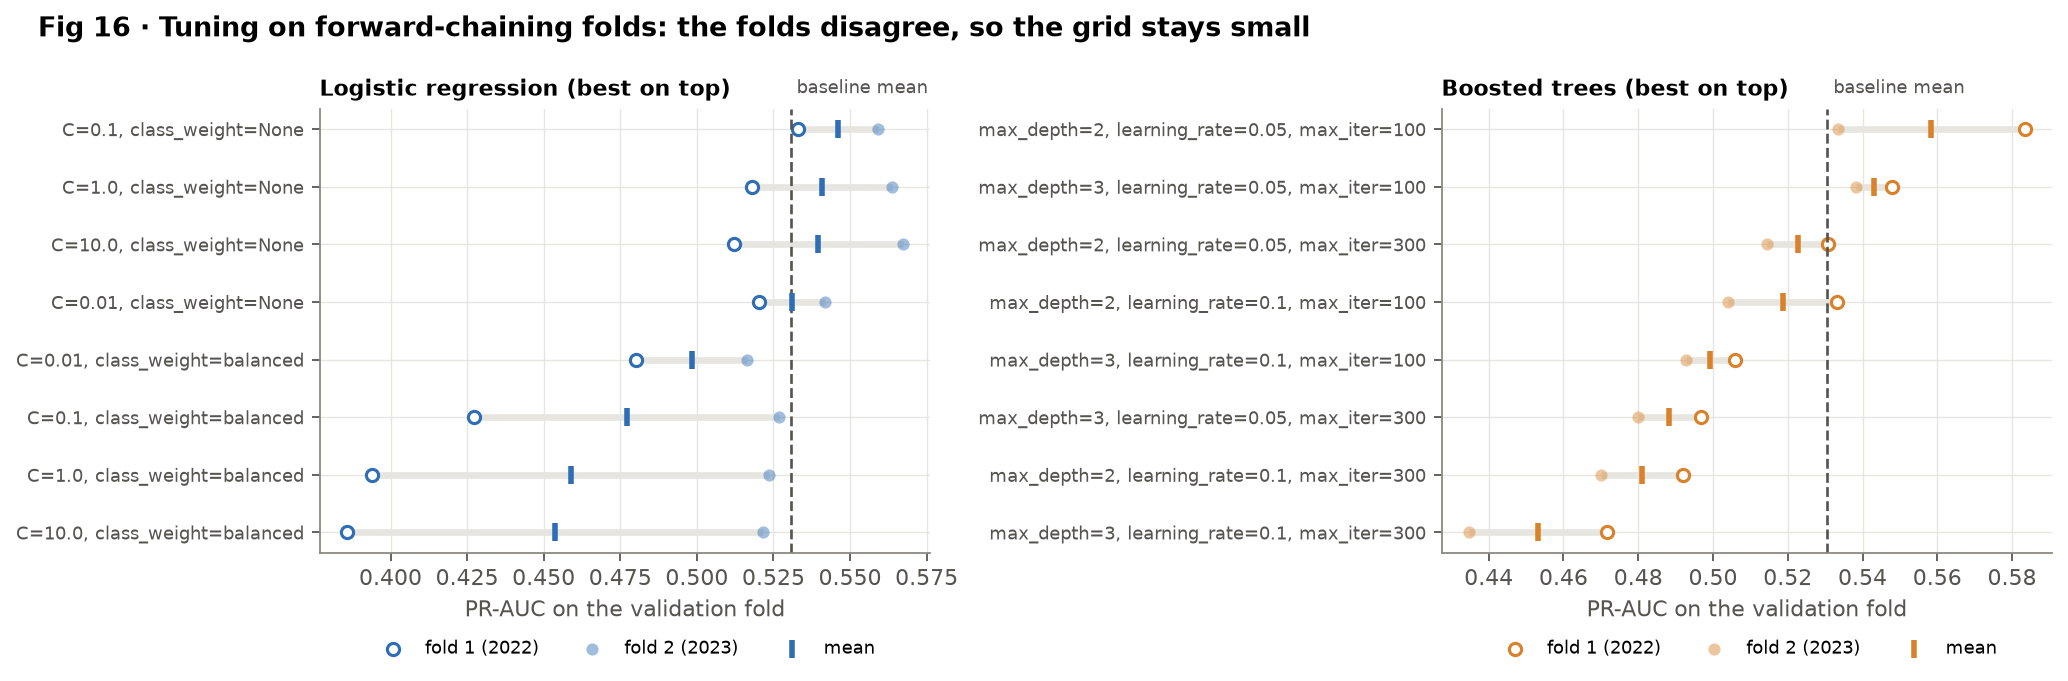

In [4]:
show(MP.fig_cv_tuning(cv, base["PM2.5 score PR-AUC"].iloc[:2].to_numpy()))

**What tuning shows**
* **Logistic regression:** moderate regularisation (C = 0.1) is best. **Class weighting hurts**
  (0.45-0.50 vs 0.53-0.55). "Balanced" weights make each of the ~200 bad days count about 15 times,
  so the model bends towards the few positives in the training year, and those differ from year to
  year. Without weighting, the threshold (§5) handles the imbalance instead.
* **Boosted trees:** the **simplest** setting wins (depth 2, slow learning rate, 100 trees). Every
  step towards more complexity lowers the score. With ~70 bad days per year, deeper trees learn noise.
* **The two folds disagree.** On 2022, logistic regression (0.53) is *below* the baseline (0.59).
  On 2023 it is well above (0.56 vs 0.47). Two folds give a rough estimate, which is why the grids
  were kept small.

## 4 · Comparison on 2024 (validation)
Each model is refitted with its best settings on all of 2021-23, then scored on 2024.

In [5]:
models = {fam: M.fit(fam, best[fam], tr) for fam in best}
y = va.y.to_numpy()
scores = M.baseline_scores(va) | {fam: models[fam].predict_proba(va[F.FEATURES])[:, 1] for fam in models}
thr = {name: M.choose_threshold(y, s) for name, s in scores.items()}
thr["persistence"], thr["never"] = 1.0, np.inf          # fixed rules, nothing to tune
results = M.score_table(y, scores, thr, probabilities=("logreg", "boosting"))
results

,PR-AUC,ROC-AUC,Brier,threshold,alerts,caught,missed,false alarms,recall,precision,F1
model,,,,,,,,,,,
never,0.084,0.500,NaN,inf,0,0,76,0,0.000,0.000,0.000
persistence,0.435,0.799,NaN,1.000,75,48,28,27,0.632,0.640,0.636
pm25_score,0.653,0.948,NaN,4.010,94,55,21,39,0.724,0.585,0.647
logreg,0.705,0.962,0.043,0.265,89,54,22,35,0.711,0.607,0.655
boosting,0.641,0.954,0.045,0.260,98,56,20,42,0.737,0.571,0.644


**How to read this table**
* **PR-AUC** compares *ranking* across all thresholds. **Threshold → recall/precision** is what the
  public would actually experience: for each model, the cut-off that catches ≥ 70% of 2024's bad
  days with the fewest false alarms.
* **Brier score** (mean squared error of the probabilities, lower is better) only applies to the
  two models, which output probabilities.
* The baseline's cut-off of 4.01 on the log scale means **"alert if today's PM2.5 > 55 µg/m³"**, a
  rule anyone can apply.

PM2.5-score cut-off: log 4.010  =  55.2 µg/m³
Logistic-regression cut-off: probability 0.265


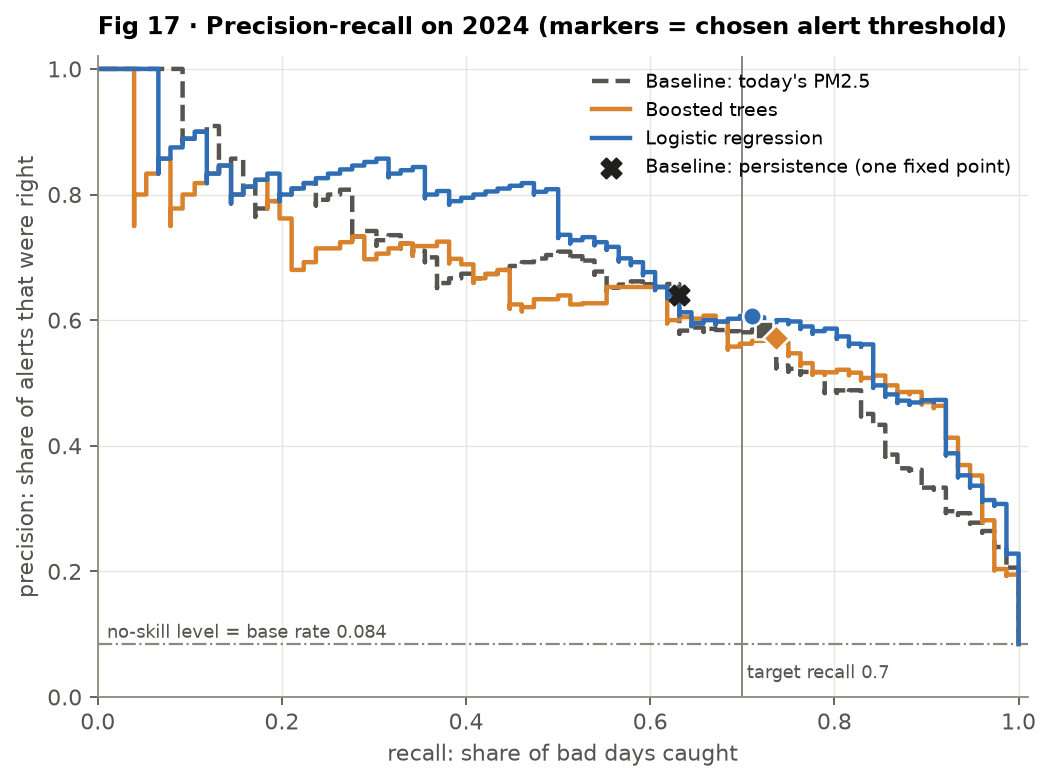

In [6]:
print(f"PM2.5-score cut-off: log {thr['pm25_score']:.3f}  =  {np.exp(thr['pm25_score']):.1f} µg/m³")
print(f"Logistic-regression cut-off: probability {thr['logreg']:.3f}")
pers = results.loc["persistence"]
show(MP.fig_pr_curves(y, scores, thr, (pers.recall, pers.precision), y.mean(), M.TARGET_RECALL))

**Result on 2024.** Logistic regression ranks best (PR-AUC 0.71 vs 0.65 for the baseline). At the
alert threshold it catches 54 of 76 bad days with 35 false alarms. The baseline catches 55 with 39
false alarms. Boosted trees are no better than the baseline (0.64). The persistence point sits
inside the curves: it is just one point on the PM2.5 score's curve (cut-off 60 instead of 55).

## 5 · Is the difference real? Block bootstrap
2024 has only 76 bad days. Re-sampling 2024 shows how much PR-AUC could move by chance. Neighbouring
days are correlated (notebook 02 §4), and so are the four stations on the same day (§5 there:
Spearman 0.63-0.93). So we resample **whole city-wide weeks**: all stations' days in a week stay
together as one block.

*Correction after review:* an earlier version resampled station-weeks, which treated same-day
stations as independent and made every interval about 1.5× too narrow. The model, its settings and
its threshold were not affected; only the width of the intervals changed.

In [7]:
pairs = [("logreg", "pm25_score"), ("boosting", "pm25_score"), ("boosting", "logreg")]
bs_2024 = M.block_bootstrap(va, {k: scores[k] for k in ["pm25_score", "logreg", "boosting"]}, pairs=pairs)
print("blocks resampled:", bs_2024.attrs["blocks"])
bs_2024

blocks resampled: 53


,PR-AUC (point),2.5%,97.5%
pm25_score,0.653,0.534,0.765
logreg,0.705,0.504,0.859
boosting,0.641,0.500,0.774
logreg - pm25_score,0.052,-0.080,0.158
boosting - pm25_score,-0.012,-0.132,0.098
boosting - logreg,-0.064,-0.159,0.067


All three intervals for the *differences* include 0. On 2024 alone we **cannot** say that
either model is better than the baseline, or that the two models differ.

### More evidence without touching the test year
The two CV folds also produced honest out-of-sample predictions: 2022 from a model that only
saw 2021, and 2023 from one that only saw 2021-22. Pooling them with 2024 triples the number of bad
days. (Caveat: the settings were picked on those same folds, so 2022-23 is very slightly
optimistic for the models.)

In [8]:
oos = M.out_of_sample(tr, va, best)
names = ["pm25_score", "logreg", "boosting"]
print(f"pooled 2022-24: {len(oos)} rows, {int(oos.y.sum())} bad days")
by_year = oos.groupby(oos.target_date.dt.year).apply(
    lambda g: pd.Series({n: M.average_precision_score(g.y, g[n]) for n in names}))
display(by_year)
bs_pool = M.block_bootstrap(oos, {n: oos[n].to_numpy() for n in names}, pairs=pairs[:2])
bs_pool

pooled 2022-24: 3041 rows, 217 bad days


,pm25_score,logreg,boosting
target_date,,,
2022,0.591,0.533,0.583
2023,0.471,0.559,0.533
2024,0.653,0.705,0.641


,PR-AUC (point),2.5%,97.5%
pm25_score,0.568,0.451,0.670
logreg,0.593,0.483,0.691
boosting,0.571,0.444,0.681
logreg - pm25_score,0.025,-0.058,0.101
boosting - pm25_score,0.003,-0.064,0.070


### Where could a model add value? (hypothesis from notebook 02 §4)
Persistence cannot catch **onset days** (today is fine, tomorrow is bad). The weather and trend
features were added for exactly these days (notebook 03). So we split the pooled rows:
* **today ≤ 60:** can the model spot a coming bad day?
* **today > 60:** can the model tell which bad spells will *continue*?

*This split was motivated in advance by the EDA, but it is still a sub-group analysis of results we
have already seen, so it is evidence to test in 2025, not a conclusion.*

In [9]:
low = oos[~(oos.log_pm25 > M.LOG_LIMIT)].reset_index(drop=True)
high = oos[oos.log_pm25 > M.LOG_LIMIT].reset_index(drop=True)
print(f"today <= 60 (or missing): {len(low)} rows, {int(low.y.sum())} bad tomorrow  |  "
      f"today > 60: {len(high)} rows, {int(high.y.sum())} bad tomorrow")
bs_low = M.block_bootstrap(low, {n: low[n].to_numpy() for n in names}, pairs=pairs[:2])
bs_high = M.block_bootstrap(high, {n: high[n].to_numpy() for n in names}, pairs=pairs[:2])
display(bs_low); display(bs_high)

today <= 60 (or missing): 2828 rows, 90 bad tomorrow  |  today > 60: 213 rows, 127 bad tomorrow


,PR-AUC (point),2.5%,97.5%
pm25_score,0.213,0.154,0.301
logreg,0.303,0.207,0.420
boosting,0.261,0.194,0.346
logreg - pm25_score,0.090,-0.024,0.206
boosting - pm25_score,0.048,-0.008,0.097


,PR-AUC (point),2.5%,97.5%
pm25_score,0.691,0.583,0.795
logreg,0.756,0.650,0.842
boosting,0.710,0.568,0.830
logreg - pm25_score,0.064,-0.007,0.123
boosting - pm25_score,0.018,-0.086,0.115


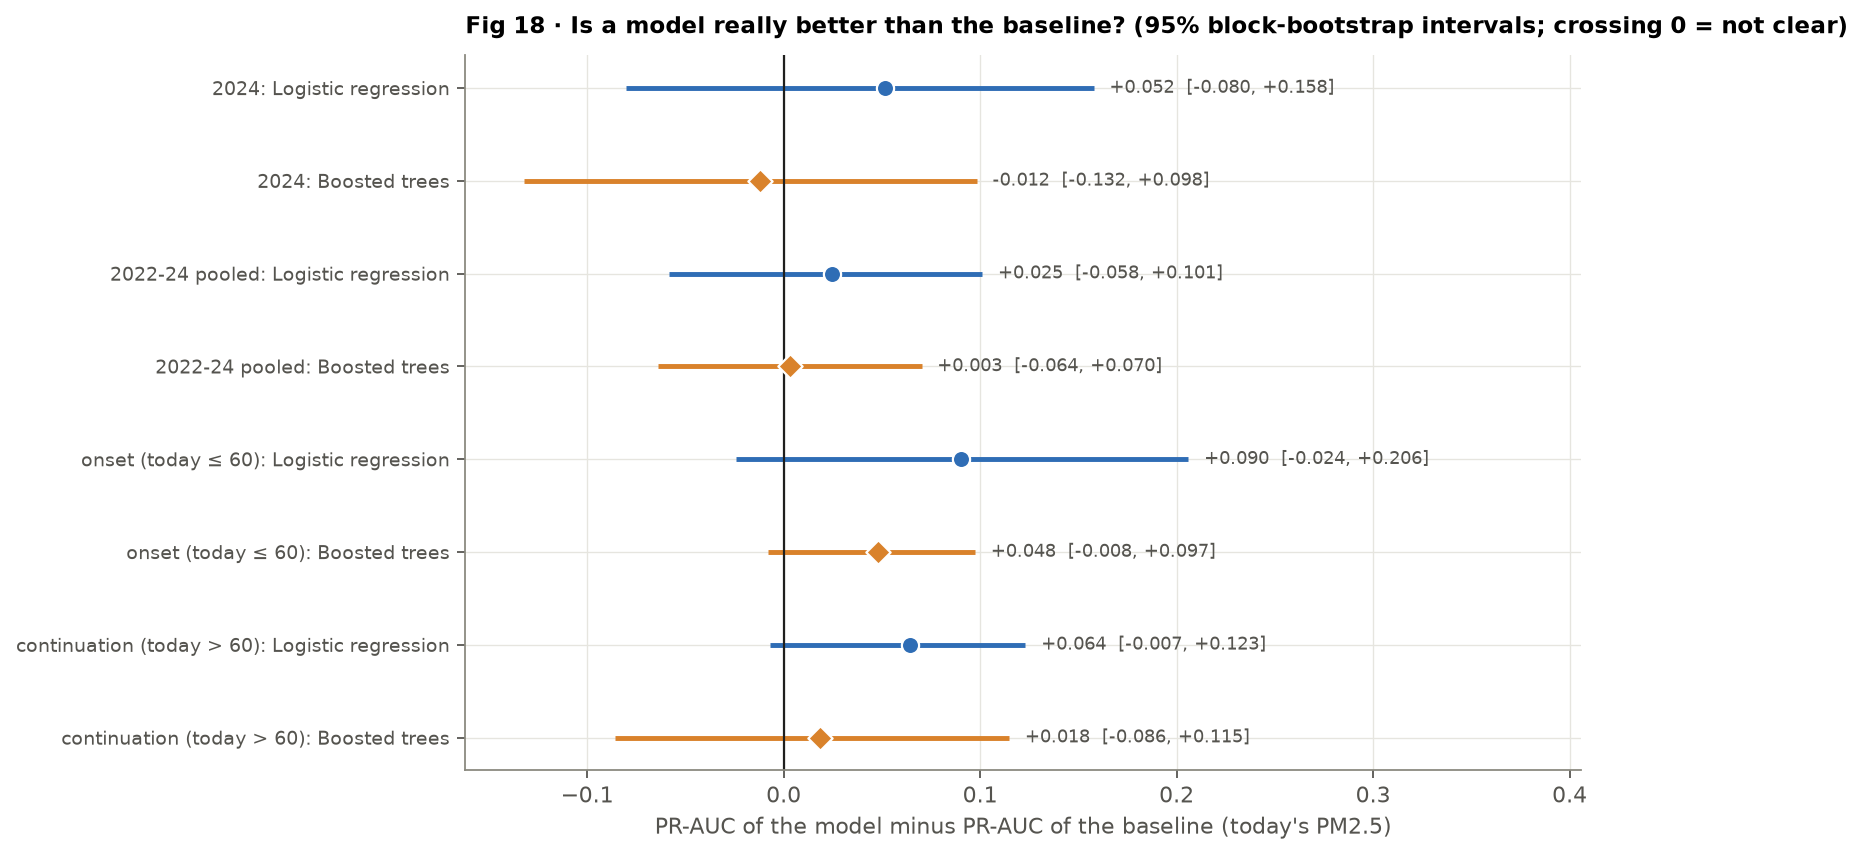

In [10]:
diffs = []
for comp, table in [("2024", bs_2024), ("2022-24 pooled", bs_pool),
                    ("onset (today ≤ 60)", bs_low), ("continuation (today > 60)", bs_high)]:
    for fam in ["logreg", "boosting"]:
        r = table.loc[f"{fam} - pm25_score"]
        diffs.append({"comparison": comp, "model": fam, "point": r["PR-AUC (point)"],
                      "lo": r["2.5%"], "hi": r["97.5%"]})
show(MP.fig_differences(pd.DataFrame(diffs)))

**Reading Fig 18.**
* **Logistic regression is ahead of the baseline in every comparison.** The gap is +0.05 on 2024,
  +0.03 pooled, +0.09 on onset days and +0.06 on continuation days.
* But **every interval includes 0**. The continuation gap comes closest (−0.01 to +0.12).
* Boosted trees are never clearly better than the baseline.

**Honest summary:** the model gives a consistent but **modest** improvement over "today's PM2.5",
and we cannot rule out that it is luck. This is common in air-quality forecasting: tomorrow's air
mostly looks like today's, and the information available at the end of today adds only a little.

## 6 · What the models learned

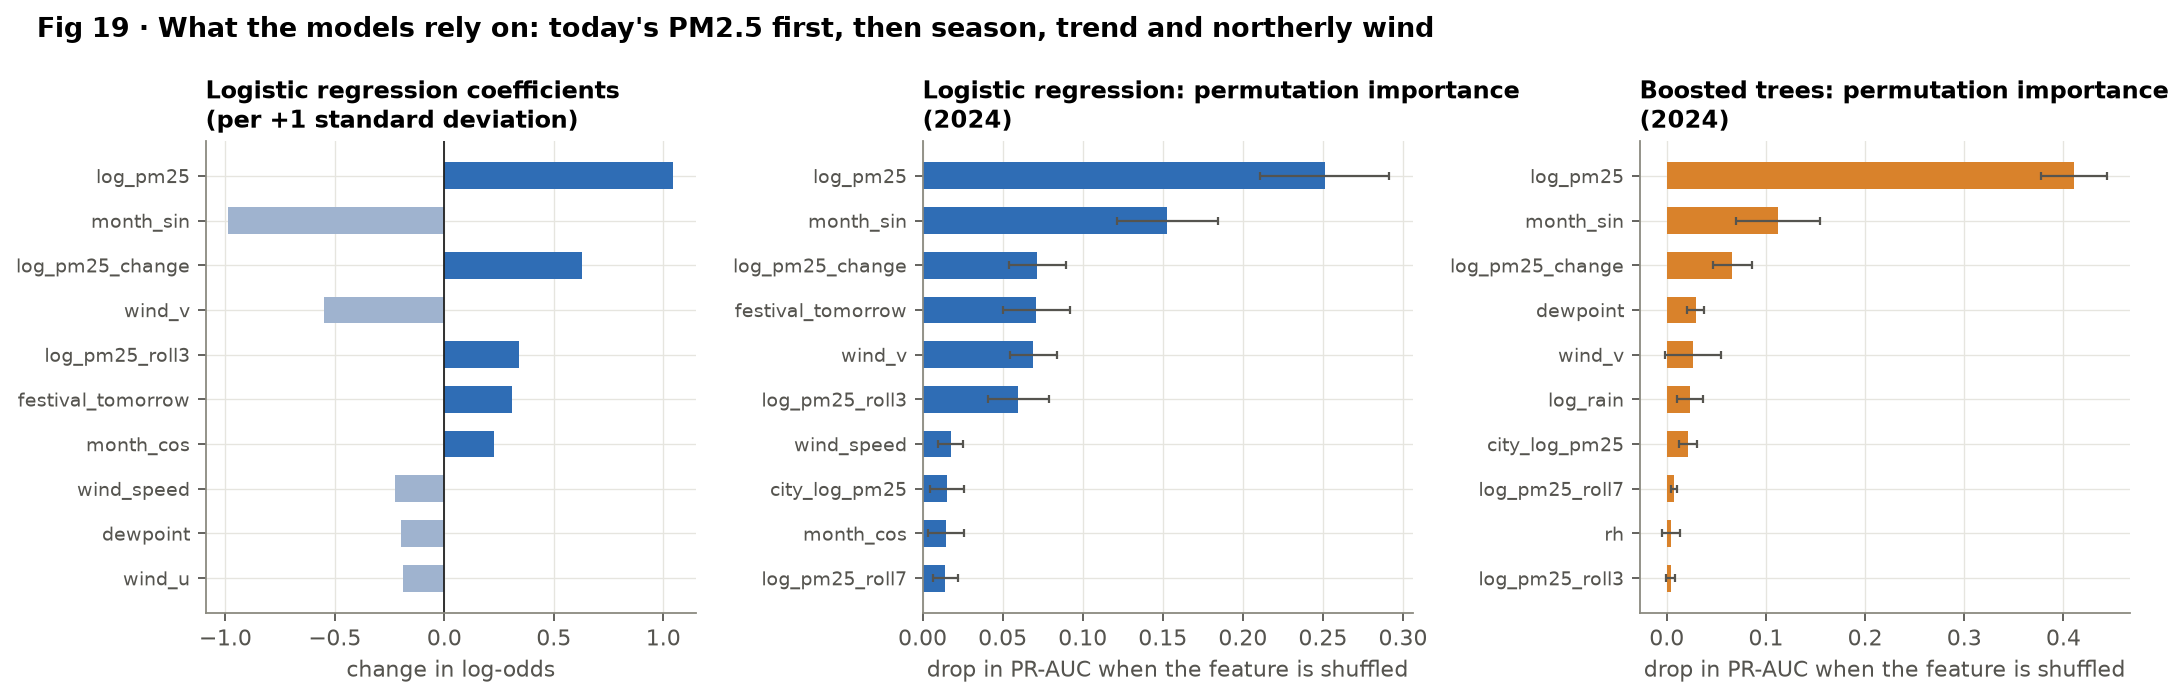

,LR coefficient,LR importance (2024),trees importance (2024)
log_pm25,1.046,0.251,0.411
month_sin,-0.989,0.153,0.112
log_pm25_change,0.629,0.072,0.066
festival_tomorrow,0.307,0.071,0.000
wind_v,-0.551,0.069,0.027
log_pm25_roll3,0.343,0.060,0.004
wind_speed,-0.225,0.017,-0.003
city_log_pm25,0.188,0.015,0.021
month_cos,0.229,0.014,0.000
log_pm25_roll7,0.123,0.014,0.007


In [11]:
coefs = M.logreg_coefficients(models["logreg"])
perm_lr = M.perm_importance(models["logreg"], va)
perm_tree = M.perm_importance(models["boosting"], va)
show(MP.fig_interpretation(coefs, perm_lr, perm_tree))
pd.DataFrame({"LR coefficient": coefs, "LR importance (2024)": perm_lr["mean drop in PR-AUC"],
              "trees importance (2024)": perm_tree["mean drop in PR-AUC"]}).sort_values(
    "LR importance (2024)", ascending=False).head(10)

**Does this match the EDA? Yes, in the expected order:**
1. **Today's PM2.5** dominates both models (H2, persistence).
2. **Season** (`month_sin`). The sine part is lowest in October and highest in April, so a negative
   weight means risk peaks around Oct-Dec and is lowest around Apr-Jun (H1).
3. **Trend** (`log_pm25_change`): a rising day is riskier. This is the onset signal persistence lacks.
4. **Northerly wind** (`wind_v` negative → more risk) and **festival tomorrow** (H3, §8).

Two cautions for the viva:
* **The city-wide mean gets little weight** even though it scored 0.39 on its own. It is 0.78
  correlated with today's own PM2.5 (notebook 03 §3), so once today's value is in the model it adds
  little. This is the "correlated features share credit" effect.
* A coefficient is the effect of a feature **with the others held fixed**. It is not a causal effect.

## 7 · Decision, frozen before the test year
The pre-written rule required a model to *clearly* beat the baseline. Logistic regression did not
do that clearly (§5). Rather than quietly relaxing the rule, the plan was adjusted **in the open,
before 2025 was looked at** (Rohan's decision):

* **Primary model:** logistic regression, settings C = 0.1 and no class weights, **trained on
  2021-23**, alert threshold chosen on 2024.
* **Reference:** the PM2.5-score baseline with its 2024 cut-off (alert if today > 55 µg/m³).
  Persistence and "never alert" are reported too.
* **Both are evaluated on 2025 exactly once** and reported as they come out. Nothing is chosen
  after seeing the test.
* Boosted trees are dropped: no better than the baseline on any comparison, and more complex.

The choice is written to `reports/model_choice.json` so stage 7 reads it instead of re-deciding.

In [12]:
choice = {
    "frozen_before_test": True,
    "primary": {"family": "logreg", "params": best["logreg"], "trained_on_target_years": [2021, 2022, 2023],
                "threshold_probability": thr["logreg"], "chosen_on": "2024 validation, recall >= 0.7"},
    "reference": {"family": "pm25_score", "threshold_log_pm25": thr["pm25_score"],
                  "threshold_ugm3": float(np.exp(thr["pm25_score"]))},
    "also_reported": ["persistence", "never"],
    "dropped": {"boosting": "not clearly better than the baseline in any comparison (Fig 18)"},
    "validation_2024": results.loc[["pm25_score", "logreg"], ["PR-AUC", "recall", "precision", "F1"]].to_dict("index"),
}
path = M.save_choice(choice)
print("saved", path.relative_to(C.ROOT))
print(path.read_text(encoding="utf-8"))

saved reports\model_choice.json
{
  "frozen_before_test": true,
  "primary": {
    "family": "logreg",
    "params": {
      "C_": 0.1,
      "class_weight": null
    },
    "trained_on_target_years": [
      2021,
      2022,
      2023
    ],
    "threshold_probability": 0.26477683616930997,
    "chosen_on": "2024 validation, recall >= 0.7"
  },
  "reference": {
    "family": "pm25_score",
    "threshold_log_pm25": 4.010238052925101,
    "threshold_ugm3": 55.16
  },
  "also_reported": [
    "persistence",
    "never"
  ],
  "dropped": {
    "boosting": "not clearly better than the baseline in any comparison (Fig 18)"
  },
  "validation_2024": {
    "pm25_score": {
      "PR-AUC": 0.6532695905838665,
      "recall": 0.7236842105263158,
      "precision": 0.5851063829787234,
      "F1": 0.6470588235294118
    },
    "logreg": {
      "PR-AUC": 0.7049164841962243,
      "recall": 0.7105263157894737,
      "precision": 0.6067415730337079,
      "F1": 0.6545454545454545
    }
  }
}



## 8 · Summary: hand-off to stage 7 (Evaluate)

| | Today's PM2.5 (baseline) | Logistic regression | Boosted trees |
|---|---|---|---|
| CV mean PR-AUC (2022, 2023) | 0.53 | 0.55 | 0.56 |
| 2024 PR-AUC | 0.65 | **0.71** | 0.64 |
| 2024 at the alert threshold | 55 caught, 39 false alarms | 54 caught, 35 false alarms | 56 caught, 42 false alarms |
| Clearly better than the baseline? | — | no: ahead in every comparison, but every interval includes 0 | no |

**Stage 7 will:** score the frozen primary model and the reference on 2025 once; carry out error
analysis (which days and stations are missed? onset days? festivals?); check calibration under the
6% → 13% base-rate shift; and run the D+1-weather upper bound ("what would a perfect weather
forecast add?").